# Tugas 2
Perbandingan Fitur **CountVectorizer** vs **TF-IDF** pada Naive Bayes

**Dataset:** `spam.csv` (SMS Spam Collection).

Dua model **Multinomial Naive Bayes** dibandingkan:

1. Fitur `CountVectorizer` + `stop_words='english'`
2. Fitur `TfidfVectorizer` + `stop_words='english'`

Lalu disimpulkan fitur mana yang lebih baik untuk kasus ini.

### Langkah 1 - Load Data & Preprocessing

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv('spam.csv', encoding='latin-1')

# Ambil 2 kolom berguna, lalu rename
df = df.drop(df.columns[2:], axis=1)
df = df.rename(columns={'v1': 'Labels', 'v2': 'SMS'})

# Encode label
df['Labels'] = df['Labels'].map({'spam': 1, 'ham': 0})

df.head()

,Labels,SMS
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [2]:
print(df['Labels'].value_counts())
print('\nMissing:', df.isna().sum().sum())

Labels
0    4825
1     747
Name: count, dtype: int64

Missing: 0


Kelas **tidak seimbang** (ham ≈ 87%, spam ≈ 13%). Karena itu, selain akurasi kita juga lihat **precision/recall** pada kelas spam.

In [3]:
X = df['SMS'].to_numpy(dtype=object)
y = df['Labels'].to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=50, stratify=y
)

print('Train:', len(X_train), '| Test:', len(X_test))

Train: 4457 | Test: 1115


### Langkah 2 - Model 1: MultinomialNB + CountVectorizer (stop_words)
`CountVectorizer` menghitung **frekuensi kemunculan kata**.

In [4]:
cv = CountVectorizer(stop_words='english')
X_train_cv = cv.fit_transform(X_train)
X_test_cv = cv.transform(X_test)

print('Jumlah kata unik (fitur):', len(cv.get_feature_names_out()))
print('Dimensi train:', X_train_cv.shape)

mnb_cv = MultinomialNB()
mnb_cv.fit(X_train_cv, y_train)

acc_train_cv = accuracy_score(y_train, mnb_cv.predict(X_train_cv))
acc_test_cv = accuracy_score(y_test, mnb_cv.predict(X_test_cv))

print(f'Akurasi train (CountVectorizer): {acc_train_cv:.4f}')
print(f'Akurasi test  (CountVectorizer): {acc_test_cv:.4f}')

Jumlah kata unik (fitur): 7422
Dimensi train: (4457, 7422)
Akurasi train (CountVectorizer): 0.9939
Akurasi test  (CountVectorizer): 0.9821


In [5]:
y_pred_cv = mnb_cv.predict(X_test_cv)
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_cv))
print('\nLaporan Klasifikasi:\n', classification_report(y_test, y_pred_cv, target_names=['ham', 'spam']))

Confusion Matrix:
 [[960   6]
 [ 14 135]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.96      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



### Langkah 3 - Model 2: MultinomialNB + TF-IDF (stop_words)
`TfidfVectorizer` memberi bobot **TF × IDF**: kata yang sering muncul di banyak dokumen (kurang informatif) ditekan, kata yang khas pada dokumen tertentu dinaikkan.

In [6]:
tfidf = TfidfVectorizer(stop_words='english')
X_train_tf = tfidf.fit_transform(X_train)
X_test_tf = tfidf.transform(X_test)

print('Jumlah kata unik (fitur):', len(tfidf.get_feature_names_out()))
print('Dimensi train:', X_train_tf.shape)

mnb_tf = MultinomialNB()
mnb_tf.fit(X_train_tf, y_train)

acc_train_tf = accuracy_score(y_train, mnb_tf.predict(X_train_tf))
acc_test_tf = accuracy_score(y_test, mnb_tf.predict(X_test_tf))

print(f'Akurasi train (TF-IDF): {acc_train_tf:.4f}')
print(f'Akurasi test  (TF-IDF): {acc_test_tf:.4f}')

Jumlah kata unik (fitur): 7422
Dimensi train: (4457, 7422)
Akurasi train (TF-IDF): 0.9843
Akurasi test  (TF-IDF): 0.9731


In [7]:
y_pred_tf = mnb_tf.predict(X_test_tf)
print('Confusion Matrix:\n', confusion_matrix(y_test, y_pred_tf))
print('\nLaporan Klasifikasi:\n', classification_report(y_test, y_pred_tf, target_names=['ham', 'spam']))

Confusion Matrix:
 [[966   0]
 [ 30 119]]

Laporan Klasifikasi:
               precision    recall  f1-score   support

         ham       0.97      1.00      0.98       966
        spam       1.00      0.80      0.89       149

    accuracy                           0.97      1115
   macro avg       0.98      0.90      0.94      1115
weighted avg       0.97      0.97      0.97      1115



### Langkah 4 - Perbandingan Hasil

In [8]:
from sklearn.metrics import precision_score, recall_score, f1_score

def ringkas(nama, y_true, y_pred):
    return {
        'Fitur': nama,
        'Akurasi': accuracy_score(y_true, y_pred),
        'Precision (spam)': precision_score(y_true, y_pred),
        'Recall (spam)': recall_score(y_true, y_pred),
        'F1 (spam)': f1_score(y_true, y_pred),
    }

banding = pd.DataFrame([
    ringkas('CountVectorizer', y_test, y_pred_cv),
    ringkas('TF-IDF', y_test, y_pred_tf),
])
banding.iloc[:, 1:] = banding.iloc[:, 1:].round(4)
banding

,Fitur,Akurasi,Precision (spam),Recall (spam),F1 (spam)
0,CountVectorizer,0.9821,0.9574,0.9060,0.9310
1,TF-IDF,0.9731,1.0000,0.7987,0.8881


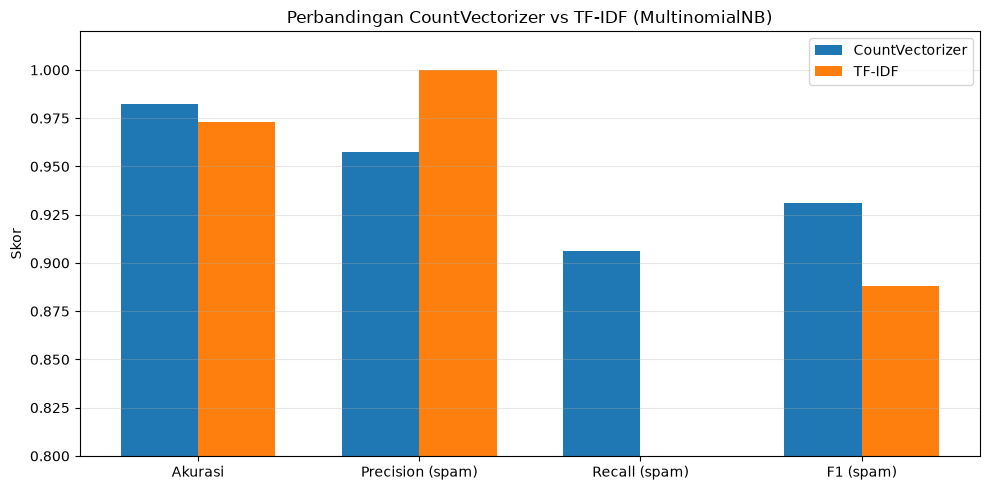

In [9]:
metrik = ['Akurasi', 'Precision (spam)', 'Recall (spam)', 'F1 (spam)']
x = np.arange(len(metrik))
w = 0.35

plt.figure(figsize=(10, 5))
plt.bar(x - w/2, banding.iloc[0, 1:].values.astype(float), w, label='CountVectorizer')
plt.bar(x + w/2, banding.iloc[1, 1:].values.astype(float), w, label='TF-IDF')
plt.xticks(x, metrik)
plt.ylim(0.8, 1.02)
plt.ylabel('Skor')
plt.title('Perbandingan CountVectorizer vs TF-IDF (MultinomialNB)')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### Kesimpulan

* Kedua pendekatan memberi performa **sangat tinggi** (akurasi > 0,97) karena Naive Bayes memang kuat pada klasifikasi teks.
* **CountVectorizer** menghitung frekuensi kata mentah, sehingga kata yang sangat sering muncul (mis. "u", "im", "get") mendominasi — cocok karena pada SMS spam kata-kata promo memang berulang.
* **TF-IDF** menekan kata yang muncul di hampir semua pesan dan menonjolkan kata yang khas. Pada dataset ini TF-IDF **sedikit lebih rendah**: akurasi 0,9731 vs 0,9821, serta recall spam 0,80 vs 0,91 (F1 spam 0,888 vs 0,931). TF-IDF justru mencapai **precision sempurna (1,00)** — ketika menandai spam hampir selalu benar — tetapi lebih banyak spam yang lolos.
* Pengaruh `stop_words='english'` kecil untuk SMS karena banyak kata non-baku/asing ("u", "2", "dun") tidak termasuk daftar stopword bahasa Inggris.
* **Rekomendasi:** untuk kasus `spam.csv` ini **CountVectorizer lebih baik** (akurasi dan F1 spam lebih tinggi). TF-IDF unggul pada *precision* sehingga cocok bila prioritasnya meminimalkan salah-tandai SMS normal sebagai spam, tetapi pada dataset ini ia melewatkan lebih banyak spam (recall lebih rendah).
* Catatan metodologis: split dilakukan **sebelum** *fitting* vectorizer agar tidak terjadi *information leakage*, dan `stratify=y` dipakai karena kelas tidak seimbang.